In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

In [2]:
def generar_centroides_3d_distanciados(k, min_dist=4.0, rango_min=-15, rango_max=15):
    centroides = []
    intentos = 0
    max_intentos = 2000

    while len(centroides) < k and intentos < max_intentos:

        nuevo_centro = np.random.uniform(rango_min, rango_max, size=3)

        if len(centroides) == 0:
            centroides.append(nuevo_centro)
        else:
        
            distancias = np.linalg.norm(np.array(centroides) - nuevo_centro, axis=1)
        
            if np.all(distancias >= min_dist):
                centroides.append(nuevo_centro)

        intentos += 1

    return np.array(centroides)

In [3]:
num_centroides = np.random.randint(1, 21)

blob_centers = generar_centroides_3d_distanciados(k=num_centroides, min_dist=4.0, rango_min=-15, rango_max=15)
k_real = len(blob_centers)

blob_std = np.full(num_centroides, 3.0)

n_puntos = 2000
X, y = make_blobs(n_samples=n_puntos,centers=blob_centers,cluster_std=blob_std,random_state=42,)

print(f"Número de clusters generados dinámicamente: {k_real}")
print(f"Forma de la matriz X (Puntos 3D): {X.shape}")

Número de clusters generados dinámicamente: 12
Forma de la matriz X (Puntos 3D): (2000, 3)


In [4]:
kmeans = KMeans(n_clusters=k_real, random_state=42, n_init=10) #Como influye n_init con un numero mas grande o pequeño
y_pred = kmeans.fit_predict(X)

centroides_finales = kmeans.cluster_centers_

distancias = kmeans.transform(X)

In [5]:
print("=" * 60)
print(" REPORTES Y DETALLES POR CLUSTER (3D)")
print("=" * 60)

puntos_cercanos_dict = {}

for i in range(k_real):
    puntos_en_cluster = np.sum(y_pred == i)

    indices_cluster = np.where(y_pred == i)[0]
    distancias_al_centroide = distancias[indices_cluster, i]

    indices_5_cercanos = indices_cluster[np.argsort(distancias_al_centroide)[:5]]
    puntos_5_cercanos = X[indices_5_cercanos]
    puntos_cercanos_dict[i] = puntos_5_cercanos

    print(f"\n--- CLUSTER {i} ---")
    print(
        f" Ubicación del centroide (x1, x2, x3): [{centroides_finales[i, 0]:.3f}, {centroides_finales[i, 1]:.3f}, {centroides_finales[i, 2]:.3f}]"
    )
    print(f" Número de puntos asignados: {puntos_en_cluster}")
    print(" 5 Puntos más cercanos al centroide:")
    for idx, punto in enumerate(puntos_5_cercanos, 1):
        dist_val = np.linalg.norm(punto - centroides_finales[i])
        print(
            f"   Punto {idx}: ({punto[0]:.3f}, {punto[1]:.3f}, {punto[2]:.3f}) | Distancia: {dist_val:.3f}"
        )

 REPORTES Y DETALLES POR CLUSTER (3D)

--- CLUSTER 0 ---
 Ubicación del centroide (x1, x2, x3): [-5.558, 3.405, -7.759]
 Número de puntos asignados: 161
 5 Puntos más cercanos al centroide:
   Punto 1: (-5.611, 3.397, -7.288) | Distancia: 0.474
   Punto 2: (-5.280, 3.799, -7.650) | Distancia: 0.495
   Punto 3: (-4.752, 3.658, -7.496) | Distancia: 0.886
   Punto 4: (-4.866, 2.977, -8.578) | Distancia: 1.154
   Punto 5: (-5.002, 4.551, -7.339) | Distancia: 1.341

--- CLUSTER 1 ---
 Ubicación del centroide (x1, x2, x3): [-2.600, -5.090, 12.560]
 Número de puntos asignados: 159
 5 Puntos más cercanos al centroide:
   Punto 1: (-2.165, -4.721, 12.406) | Distancia: 0.591
   Punto 2: (-2.659, -5.522, 11.723) | Distancia: 0.944
   Punto 3: (-3.401, -4.404, 12.543) | Distancia: 1.056
   Punto 4: (-2.926, -3.888, 12.219) | Distancia: 1.292
   Punto 5: (-3.937, -4.956, 12.758) | Distancia: 1.359

--- CLUSTER 2 ---
 Ubicación del centroide (x1, x2, x3): [-3.235, -7.852, -6.030]
 Número de puntos a

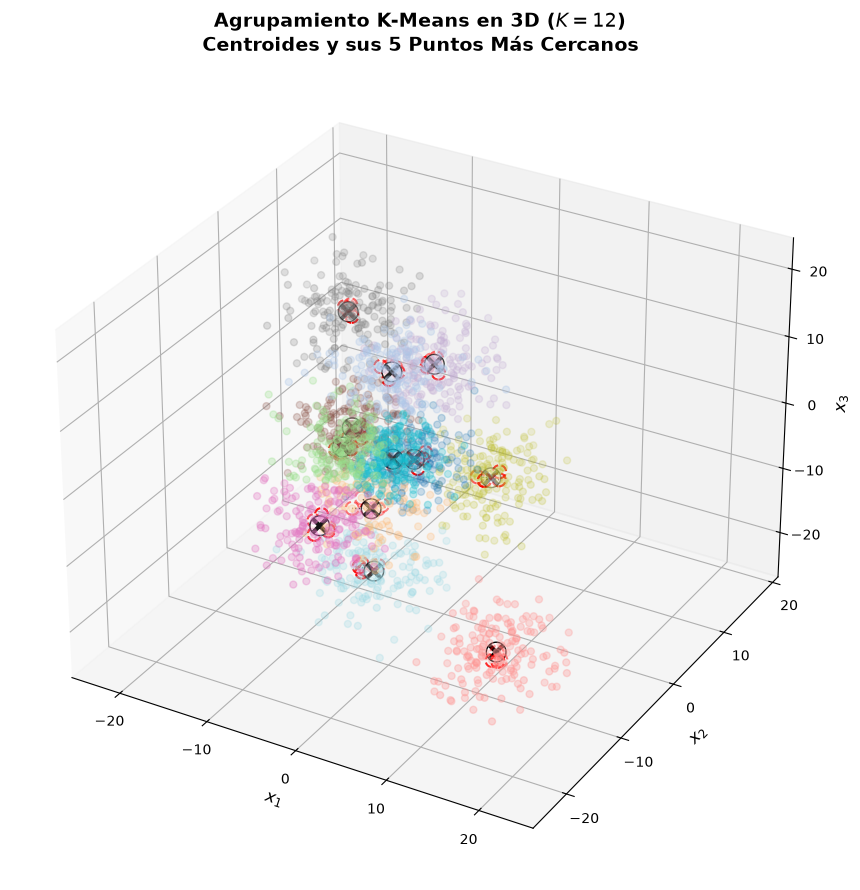

In [6]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    c=y_pred,
    cmap='tab20',
    s=25,
    alpha=0.6,
    depthshade=True,
)

ax.scatter(
    centroides_finales[:, 0],
    centroides_finales[:, 1],
    centroides_finales[:, 2],
    marker='o',
    c='white',
    s=200,
    edgecolors='black',
    zorder=10,
)
ax.scatter(
    centroides_finales[:, 0],
    centroides_finales[:, 1],
    centroides_finales[:, 2],
    marker='x',
    c='black',
    s=100,
    linewidths=3,
    zorder=11,
    label='Centroides Finales',
)

for i in range(k_real):
    puntos_5 = puntos_cercanos_dict[i]

    ax.scatter(
        puntos_5[:, 0],
        puntos_5[:, 1],
        puntos_5[:, 2],
        s=90,
        facecolors='none',
        edgecolors='red',
        linewidths=1.5,
        linestyle='--',
    )

    for p in puntos_5:
        ax.plot(
            [centroides_finales[i, 0], p[0]],
            [centroides_finales[i, 1], p[1]],
            [centroides_finales[i, 2], p[2]],
            color='black',
            linestyle=':',
            linewidth=1,
            alpha=0.8,
        )

ax.set_xlabel('$x_1$', fontsize=12)
ax.set_ylabel('$x_2$', fontsize=12)
ax.set_zlabel('$x_3$', fontsize=12)
ax.set_title(
    f'Agrupamiento K-Means en 3D ($K = {k_real}$)\nCentroides y sus 5 Puntos Más Cercanos',
    fontsize=14,
    fontweight='bold',
)

plt.tight_layout()
plt.show()

In [7]:
X_new = np.array([[-5, 10, 3], [5, 10, 9], [8, 1, -5], [-10, 1.5, 12]])
kmeans.predict(X_new)

array([ 5,  5, 10,  8], dtype=int32)

In [8]:
kmeans.transform(X_new)

array([[12.63184147, 18.02420303, 20.08382981, 19.0770539 , 36.43406786,
        10.53935126, 13.34105295, 25.99128372, 12.87334131, 17.44807213,
        16.2286529 , 25.73979631],
       [20.87675949, 17.26696385, 24.74692752, 22.5926236 , 35.73041844,
        10.93617987, 20.67311689, 29.55084741, 19.68455318, 23.77537644,
        19.34656487, 31.16839704],
       [14.04371274, 21.39598835, 14.34039685, 18.80711338, 19.81207139,
        17.37318366, 17.92487487, 20.30736065, 27.15082064, 15.84039707,
        13.25400332, 17.38770049],
       [20.3412302 ,  9.92538619, 21.4079839 , 14.4489756 , 40.03177232,
         8.32401783, 12.66870449, 23.4634233 ,  5.19149386, 28.89148239,
        15.86794563, 29.66614643]])

In [9]:
kmeans_iter1 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=1, random_state=1)
kmeans_iter2 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=20, random_state=1)
kmeans_iter3 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=40, random_state=1)

kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",12
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",40
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](12, 3)","[[ -2.

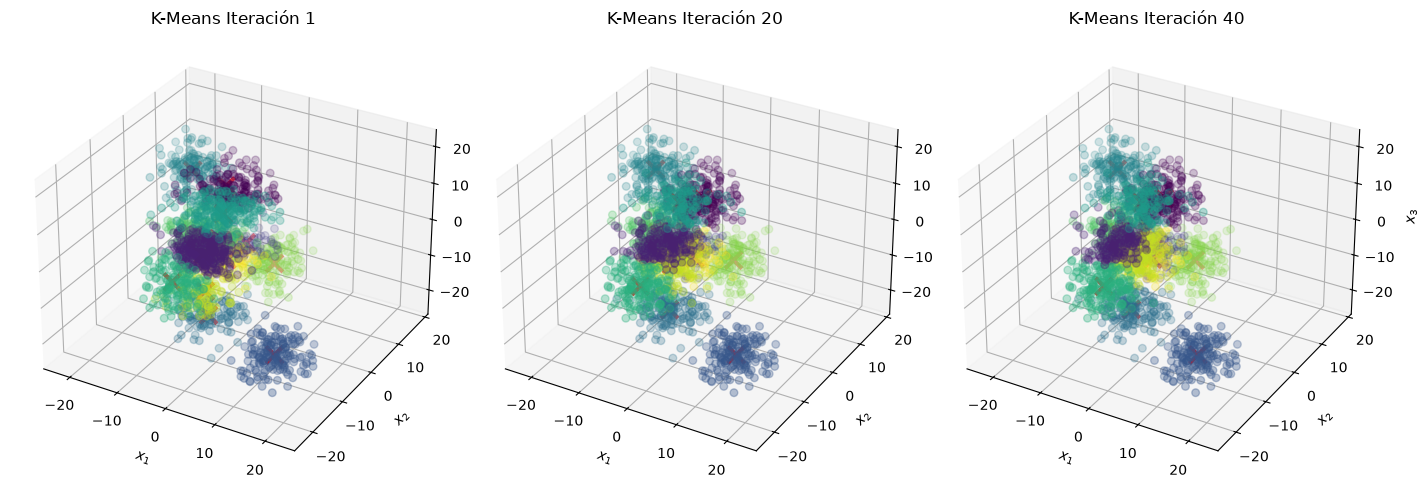

In [12]:
# 2. Crear la figura en 3D
fig = plt.figure(figsize=(14, 6))

# --- ITERACIÓN 1 (max_iter=1) ---
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
# Graficamos los puntos coloreados según la etiqueta del modelo 1
ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter1.labels_, cmap="viridis", s=30, alpha=0.6)
# Graficamos los centroides
centroids1 = kmeans_iter1.cluster_centers_
ax1.scatter(centroids1[:, 0], centroids1[:, 1], centroids1[:, 2], 
            marker="x", s=150, linewidths=3, color="r", label="Centroides")
ax1.set_title("K-Means Iteración 1", fontsize=12)
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_zlabel("$x_3$")

# --- ITERACIÓN 2 (max_iter=20) ---
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter2.labels_, cmap="viridis", s=30, alpha=0.6)
centroids2 = kmeans_iter2.cluster_centers_
ax2.scatter(centroids2[:, 0], centroids2[:, 1], centroids2[:, 2], 
            marker="x", s=150, linewidths=3, color="r")
ax2.set_title("K-Means Iteración 20", fontsize=12)
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_zlabel("$x_3$")

# --- ITERACIÓN 3 (max_iter=40) ---
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter3.labels_, cmap="viridis", s=30, alpha=0.6)
centroids3 = kmeans_iter3.cluster_centers_
ax3.scatter(centroids3[:, 0], centroids3[:, 1], centroids3[:, 2], 
            marker="x", s=150, linewidths=3, color="r")
ax3.set_title("K-Means Iteración 40", fontsize=12)
ax3.set_xlabel("$x_1$")
ax3.set_ylabel("$x_2$")
ax3.set_zlabel("$x_3$")

plt.tight_layout()
plt.show()

In [14]:
kmeans_iter1_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=1, random_state=1)
kmeans_iter2_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=20, random_state=1)
kmeans_iter3_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=40, random_state=1)

kmeans_iter1_lkn.fit(X)
kmeans_iter2_lkn.fit(X)
kmeans_iter3_lkn.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",12
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",40
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](12, 3)","[[ -2.

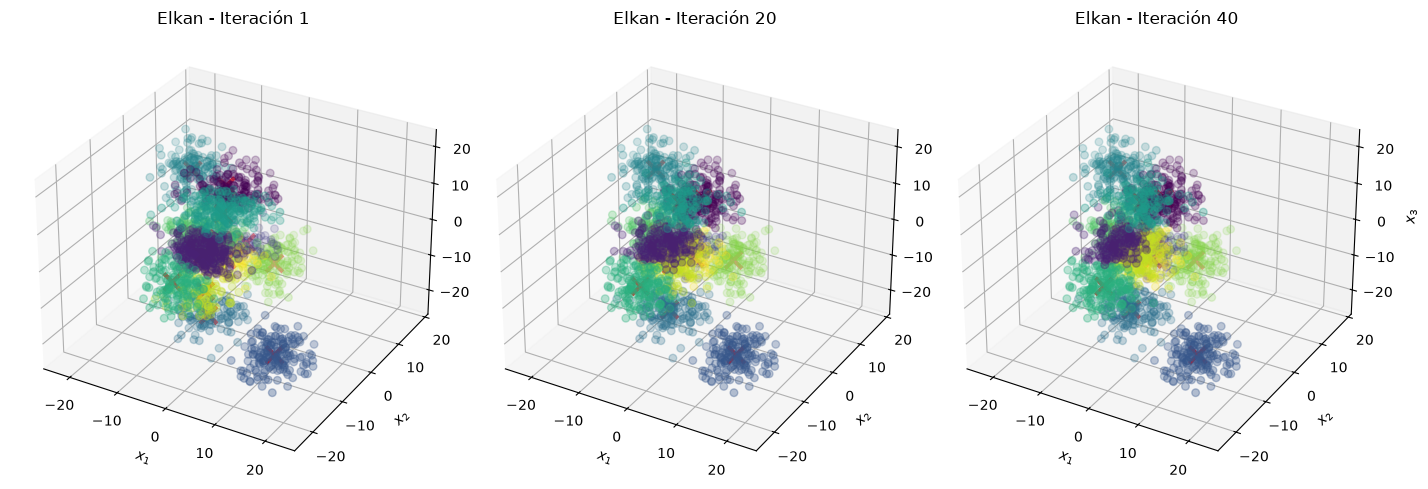

In [15]:
# 2. Crear la figura en 3D (1 fila, 3 columnas)
fig = plt.figure(figsize=(14, 6))

# --- ITERACIÓN 1 (max_iter=1, elkan) ---
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter1_lkn.labels_, cmap="viridis", s=30, alpha=0.6)
centroids1 = kmeans_iter1_lkn.cluster_centers_
ax1.scatter(centroids1[:, 0], centroids1[:, 1], centroids1[:, 2], 
            marker="x", s=150, linewidths=3, color="r", label="Centroides")
ax1.set_title("Elkan - Iteración 1", fontsize=12)
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_zlabel("$x_3$")

# --- ITERACIÓN 2 (max_iter=20, elkan) ---
ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter2_lkn.labels_, cmap="viridis", s=30, alpha=0.6)
centroids2 = kmeans_iter2_lkn.cluster_centers_
ax2.scatter(centroids2[:, 0], centroids2[:, 1], centroids2[:, 2], 
            marker="x", s=150, linewidths=3, color="r")
ax2.set_title("Elkan - Iteración 20", fontsize=12)
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_zlabel("$x_3$")

# --- ITERACIÓN 3 (max_iter=40, elkan) ---
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.scatter(X[:, 0], X[:, 1], X[:, 2], c=kmeans_iter3_lkn.labels_, cmap="viridis", s=30, alpha=0.6)
centroids3 = kmeans_iter3_lkn.cluster_centers_
ax3.scatter(centroids3[:, 0], centroids3[:, 1], centroids3[:, 2], 
            marker="x", s=150, linewidths=3, color="r")
ax3.set_title("Elkan - Iteración 40", fontsize=12)
ax3.set_xlabel("$x_1$")
ax3.set_ylabel("$x_2$")
ax3.set_zlabel("$x_3$")

plt.tight_layout()
plt.show()

In [17]:
def plot_decision_boundaries(clusterer, X, show_ylabels=True):
    fig = plt.gcf()
    ax_old = plt.gca()
    bbox = ax_old.get_position()
    ax_old.remove()
    
    ax = fig.add_axes(bbox, projection='3d')

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=clusterer.labels_, cmap="viridis", s=30, alpha=0.6)

    if hasattr(clusterer, "cluster_centers_"):
        centroids = clusterer.cluster_centers_
        ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], 
                    marker="x", s=150, linewidths=3, color="r")
        
    ax.set_xlabel("$x_1$")
    if show_ylabels:
        ax.set_ylabel("$x_2$")
    ax.set_zlabel("$x_3$")

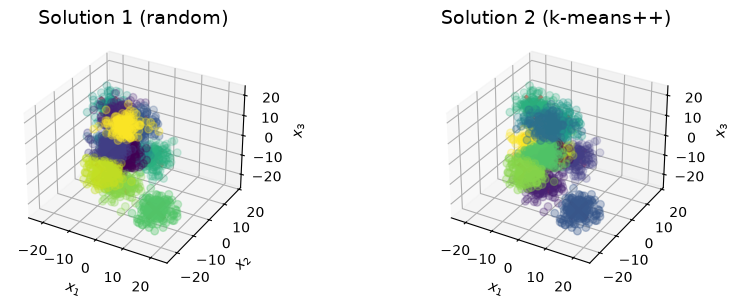

In [18]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

kmeans_rnd_init1 = KMeans(n_clusters=k_real, init="random", n_init=1, algorithm="elkan", random_state=19)
kmeans_rnd_init2 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", random_state=19)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,"Solution 1 (random)", "Solution 2 (k-means++)")

plt.show()

In [19]:
kmeans_rnd_1_inits = KMeans(n_clusters=k_real, init="random", n_init=1, algorithm="elkan", random_state=11)
kmeans_rnd_1_inits.fit(X)

kmeans_rnd_10_inits = KMeans(n_clusters=k_real, init="random", n_init=5, algorithm="elkan", random_state=11)
kmeans_rnd_10_inits.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",12
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",11
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](12, 3)","[[ -8.8

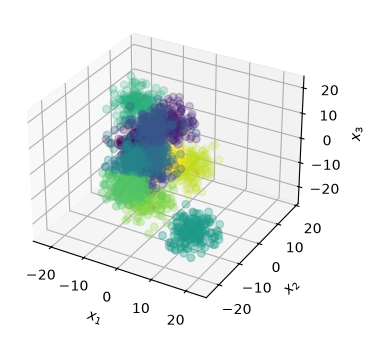

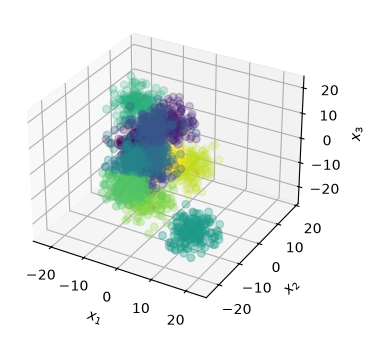

In [20]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_1_inits, X)
plt.show()

plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

In [21]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

0.3380401876225518

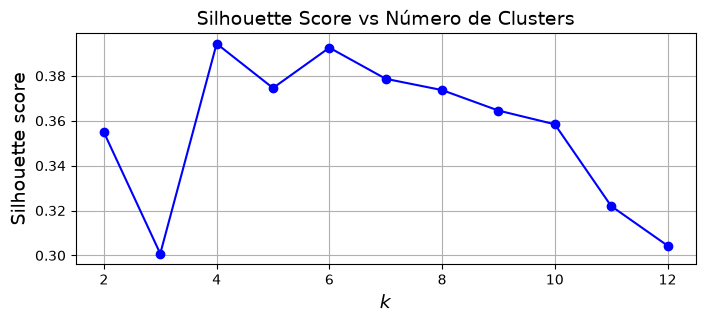

In [23]:
kmeans_per_k = [KMeans(n_clusters=k_real, random_state=42).fit(X) for k_real in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = min(20, len(blob_centers))
kmeans_per_k = [KMeans(n_clusters=k_real, random_state=42).fit(X) for k_real in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

ks = list(range(2, max_k + 1))

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

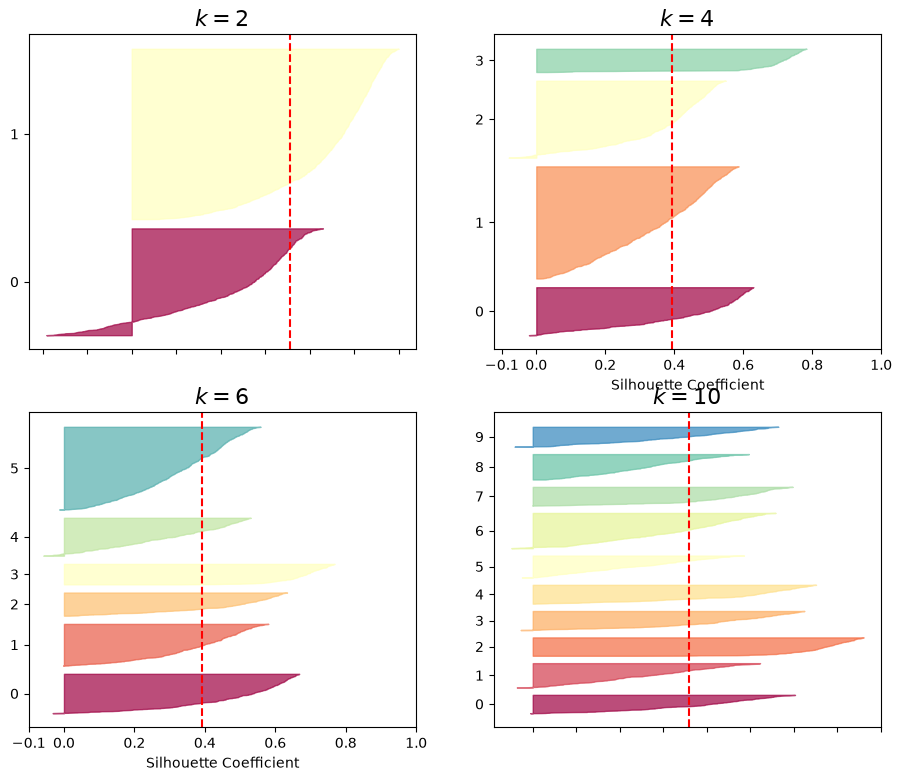

In [25]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (2, 4, 6, 10) if k <= len(kmeans_per_k)]  # Filtrar solo los ks válidos


for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)  # enumerar para evitar errores


    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (3, 4, 5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)

plt.show()